In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\ramal\Documents\CAMINO NY\credit-risk-pd-modeling\credit-risk-pd-modeling\data\raw\cs-training.csv")

df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
# eliminamos la primera columna
df = df.drop(columns=['Unnamed: 0'])

In [3]:
# eliminamos edades iguales a 0
df = df[df['age'] > 0]

In [4]:
# eliminamos los dias de mora mayores a 96/98
anom = ['NumberOfTime30-59DaysPastDueNotWorse',
'NumberOfTimes90DaysLate',
'NumberOfTime60-89DaysPastDueNotWorse']

for i in anom:
    df = df[df[i] < 90]

In [5]:
# rellenamos los valores faltantes con valores de la mediana porque es muy skewed
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(
df['MonthlyIncome'].median()
)

In [6]:
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

In [7]:
df.isnull().sum()

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

In [8]:
df.shape

(149730, 11)

In [9]:
df['SeriousDlqin2yrs'].value_counts(normalize=True)

SeriousDlqin2yrs
0    0.934021
1    0.065979
Name: proportion, dtype: float64

In [10]:
df[df['age'] < 18]['age'].value_counts()

Series([], Name: count, dtype: int64)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [12]:
# split
x = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

X_train, X_test, Y_train, Y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    stratify=y,
    random_state = 42
)

In [13]:
#scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [14]:
from imblearn.over_sampling import SMOTE

In [15]:
smote = SMOTE(random_state = 42)

X_train_smote ,Y_train_smote =smote.fit_resample(X_train_scaled,Y_train)

In [16]:
print(Y_train.value_counts())
print(Y_train_smote.value_counts())

SeriousDlqin2yrs
0    111881
1      7903
Name: count, dtype: int64
SeriousDlqin2yrs
0    111881
1    111881
Name: count, dtype: int64


In [17]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

In [18]:
from sklearn import set_config
set_config(display="text")

In [19]:
# =============================================
# EXPERIMENTO: ¿el SMOTE rompe la calibración?
# =============================================

# Modelo A: Logística CON SMOTE (igual que en la tesis)
lr_con = LogisticRegression(max_iter=1000, random_state=42)
lr_con.fit(X_train_smote, Y_train_smote)

# Modelo B: Logística SIN SMOTE (datos originales)
lr_sin = LogisticRegression(max_iter=1000, random_state=42)
lr_sin.fit(X_train_scaled, Y_train)



LogisticRegression(max_iter=1000, random_state=42)

In [20]:
# Probabilidades de default estimadas en el set de TEST
prob_con = lr_con.predict_proba(X_test_scaled)[:, 1]
prob_sin = lr_sin.predict_proba(X_test_scaled)[:, 1]

print("PD promedio CON SMOTE:", round(prob_con.mean(), 4))
print("PD promedio SIN SMOTE:", round(prob_sin.mean(), 4))
print("Tasa REAL de default: ", round(Y_test.mean(), 4))

PD promedio CON SMOTE: 0.3694
PD promedio SIN SMOTE: 0.065
Tasa REAL de default:  0.066


In [21]:
# Tasa real de default y Brier de la predicción "ingenua"
tasa_real = Y_test.mean()
brier_ingenuo = tasa_real * (1 - tasa_real)

# Tabla Comparativa
comparacion = pd.DataFrame({
    "AUC": [roc_auc_score(Y_test,prob_con), roc_auc_score(Y_test, prob_sin)],
    "Brier": [brier_score_loss(Y_test, prob_con), brier_score_loss(Y_test, prob_sin)],
    "PD promedio": [prob_con.mean(), prob_sin.mean()]
}, index=["Con SMOTE", "Sin SMOTE"])

print(comparacion.round(4))
print("\nBrier ingenuo (PD = tasa real para todos):", round(brier_ingenuo, 4))

              AUC   Brier  PD promedio
Con SMOTE  0.8122  0.1552       0.3694
Sin SMOTE  0.8072  0.0522       0.0650

Brier ingenuo (PD = tasa real para todos): 0.0616


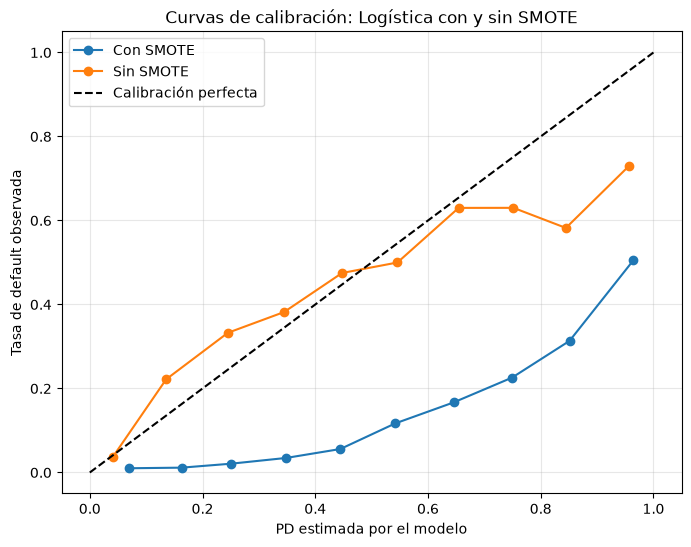

In [22]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

# Curva de cada modelo
for nombre, prob in [("Con SMOTE", prob_con), ("Sin SMOTE", prob_sin)]:
    frac_real, prob_media = calibration_curve(Y_test, prob, n_bins=10)
    plt.plot(prob_media, frac_real, marker="o", label=nombre)

# Diagonal = calibración perfecta
plt.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")

plt.xlabel("PD estimada por el modelo")
plt.ylabel("Tasa de default observada")
plt.title("Curvas de calibración: Logística con y sin SMOTE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Conclusiones

**Resultado:** entrenar con SMOTE no afectó la capacidad de discriminación del modelo, pero sí deterioró fuertemente su calibración.

- **Discriminación:** el AUC es prácticamente igual con y sin SMOTE (0,812 vs. 0,807). El modelo ordena a los clientes por riesgo de la misma manera.
- **Calibración:** con SMOTE, la PD promedio estimada es 36,9%, más de 5 veces la tasa real de default (6,6%). Su Brier score (0,155) es incluso peor que el de un benchmark ingenuo que asigna a todos la tasa promedio (0,062). La curva de calibración muestra que sobreestima la PD en todos los niveles de riesgo.
- **Sin SMOTE**, la PD promedio (6,5%) coincide con la real y el Brier baja a 0,052, mejor que el benchmark. La curva sigue de cerca la diagonal en el rango de PD bajas, donde se concentra la mayoría de los clientes, aunque subestima levemente en la zona media (10%–40%) y es más inestable en las PD altas, donde hay pocas observaciones.

**Implicancia para el negocio:** una PD sobreestimada infla las provisiones (IFRS 9) y el capital regulatorio (Basilea), y encarece o restringe el crédito a clientes que en realidad son buenos pagadores.

**Próximos pasos:**
1. Tratar los outliers de `RevolvingUtilizationOfUnsecuredLines` y el problema de `DebtRatio` cuando falta el ingreso.
2. Evaluar la recalibración de los modelos de árboles (Platt / Isotonic).
3. Validación cruzada estratificada para resultados más robustos.